In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import LabelEncoder, RobustScaler
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV, learning_curve

from sklearn.svm import SVR
from xgboost import XGBRegressor

from sklearn.metrics import r2_score, root_mean_squared_error, mean_absolute_error

#### Data Observation, Cleaning

In [2]:
# Data overview of head, tail and shape
df = pd.read_csv("assets/car.csv")

df

,MODEL,MAKE,MODEL.1,VEHICLE CLASS,ENGINE_SIZE,CYLINDERS,TRANSMISSION,FUEL,FUEL_CONSUMPTION*,Unnamed: 9,Unnamed: 10,Unnamed: 11,CO2_EMISSIONS
0,2001,ACURA,1.7EL,COMPACT,1.7,4,A4,X,9.3,7.2,8.3,34,191
1,2001,ACURA,1.7EL,COMPACT,1.7,4,M5,X,8.9,7.4,8.3,34,191
2,2001,ACURA,3.2CL,COMPACT,3.2,6,AS5,Z,13.7,8.8,11.5,25,265
3,2001,ACURA,3.2TL,MID-SIZE,3.2,6,AS5,Z,13.8,8.8,11.6,24,267
4,2001,ACURA,3.5RL,MID-SIZE,3.5,6,A4,Z,15.0,10.9,13.1,22,301
...,...,...,...,...,...,...,...,...,...,...,...,...,...
674,2001,VOLVO,V70 T5 WAGON TURBO,STATION WAGON - MID-SIZE,2.3,5,M5,Z,13.0,9.3,11.3,25,260
675,2001,VOLVO,V70 WAGON,STATION WAGON - MID-SIZE,2.4,5,A5,Z,12.8,9.3,11.2,25,258
676,2001,VOLVO,V70 WAGON,STATION WAGON - MID-SIZE,2.4,5,M5,Z,12.5,9.3,11.0,26,253
677,2001,VOLVO,V70 WAGON AWD TURBO,STATION WAGON - MID-SIZE,2.4,5,AS5,Z,14.4,10.3,12.5,23,288


In [3]:
# Standardize columns
df.columns = df.columns.str.strip().str.lower().str.replace(' ', '_').str.replace(':', '').str.replace('*', '')

In [4]:
# Check columns
df.columns

Index(['model', 'make', 'model.1', 'vehicle_class', 'engine_size', 'cylinders',
       'transmission', 'fuel', 'fuel_consumption', 'unnamed_9', 'unnamed_10',
       'unnamed_11', 'co2_emissions'],
      dtype='object')

In [5]:
# Rename features and check data info
df.rename(columns = {'model': 'year',
                     'make' : 'maker',
                     'model.1': 'model',
                    'unnamed_9': 'fuel_consumption2',
                    'unnamed_10': 'fuel_consumption3', 
                    'unnamed_11': 'fuel_consumption4'}, inplace = True)
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 679 entries, 0 to 678
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   year               679 non-null    int64  
 1   maker              679 non-null    object 
 2   model              679 non-null    object 
 3   vehicle_class      679 non-null    object 
 4   engine_size        679 non-null    float64
 5   cylinders          679 non-null    int64  
 6   transmission       679 non-null    object 
 7   fuel               679 non-null    object 
 8   fuel_consumption   679 non-null    float64
 9   fuel_consumption2  679 non-null    float64
 10  fuel_consumption3  679 non-null    float64
 11  fuel_consumption4  679 non-null    int64  
 12  co2_emissions      679 non-null    int64  
dtypes: float64(4), int64(4), object(5)
memory usage: 69.1+ KB


In [6]:
# Vehicle_class column values
df['vehicle_class'].value_counts()

vehicle_class
COMPACT                     145
PICKUP TRUCK - STANDARD     101
SUV                          98
MID-SIZE                     82
SUBCOMPACT                   62
TWO-SEATER                   31
STATION WAGON - MID-SIZE     31
FULL-SIZE                    30
VAN - CARGO                  23
VAN - PASSENGER              18
MINIVAN                      17
MINICOMPACT                  17
STATION WAGON - SMALL        12
PICKUP TRUCK - SMALL         12
Name: count, dtype: int64

In [7]:
# Numerical values overview
df.describe()

,year,engine_size,cylinders,fuel_consumption,fuel_consumption2,fuel_consumption3,fuel_consumption4,co2_emissions
count,679.0,679.000000,679.000000,679.000000,679.000000,679.000000,679.000000,679.000000
mean,2001.0,3.252577,5.798233,14.591900,10.613844,12.802798,23.107511,293.656848
std,0.0,1.203751,1.531073,3.025654,2.357724,2.685590,5.308083,60.372456
min,2001.0,1.000000,3.000000,4.900000,4.000000,4.500000,14.000000,104.000000
25%,2001.0,2.200000,4.000000,12.700000,9.000000,11.000000,19.000000,253.000000
50%,2001.0,3.000000,6.000000,14.300000,10.100000,12.300000,23.000000,283.000000
75%,2001.0,4.200000,6.000000,16.650000,12.500000,14.850000,26.000000,340.000000
max,2001.0,8.000000,12.000000,23.200000,18.000000,20.800000,63.000000,478.000000


In [8]:
# Check null values
df.isnull().sum()

year                 0
maker                0
model                0
vehicle_class        0
engine_size          0
cylinders            0
transmission         0
fuel                 0
fuel_consumption     0
fuel_consumption2    0
fuel_consumption3    0
fuel_consumption4    0
co2_emissions        0
dtype: int64

In [9]:
# Check dupicate
df.duplicated().sum()

np.int64(0)

#### Data Visualization

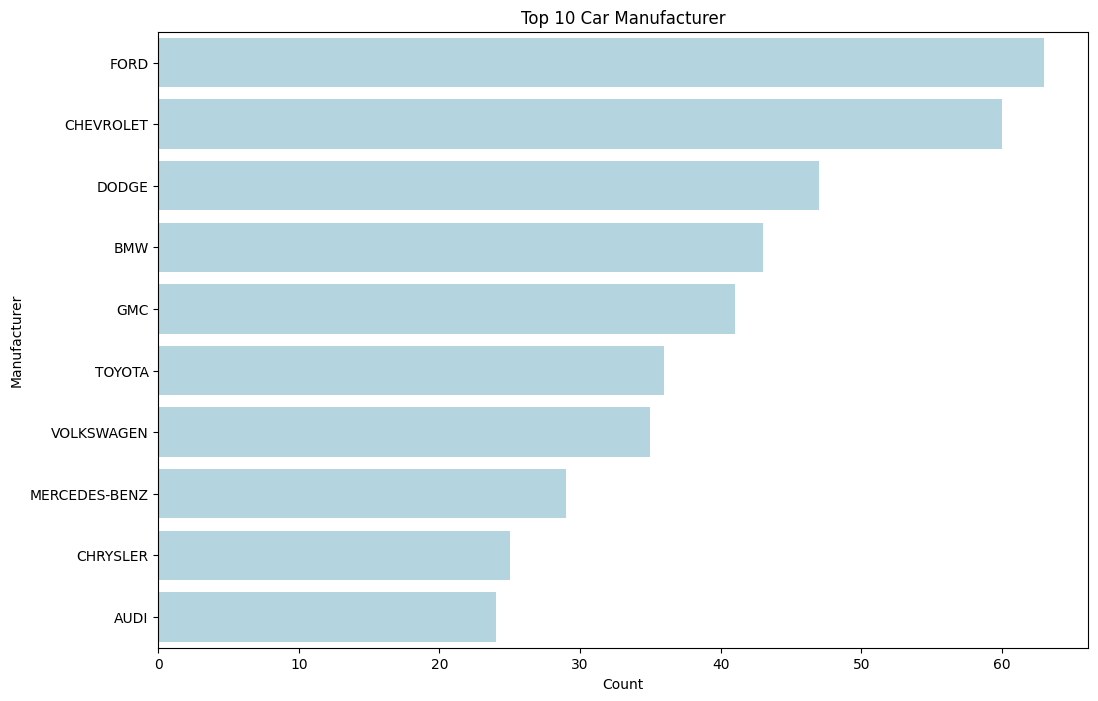

In [10]:
# Manufacturer bar chart
plt.figure(figsize = (12, 8))
sns.countplot(y = 'maker', 
            data = df,
            order = df['maker'].value_counts().nlargest(10).index,
            color = 'lightblue')
plt.title('Top 10 Car Manufacturer')
plt.xlabel('Count')
plt.ylabel('Manufacturer')
plt.show()

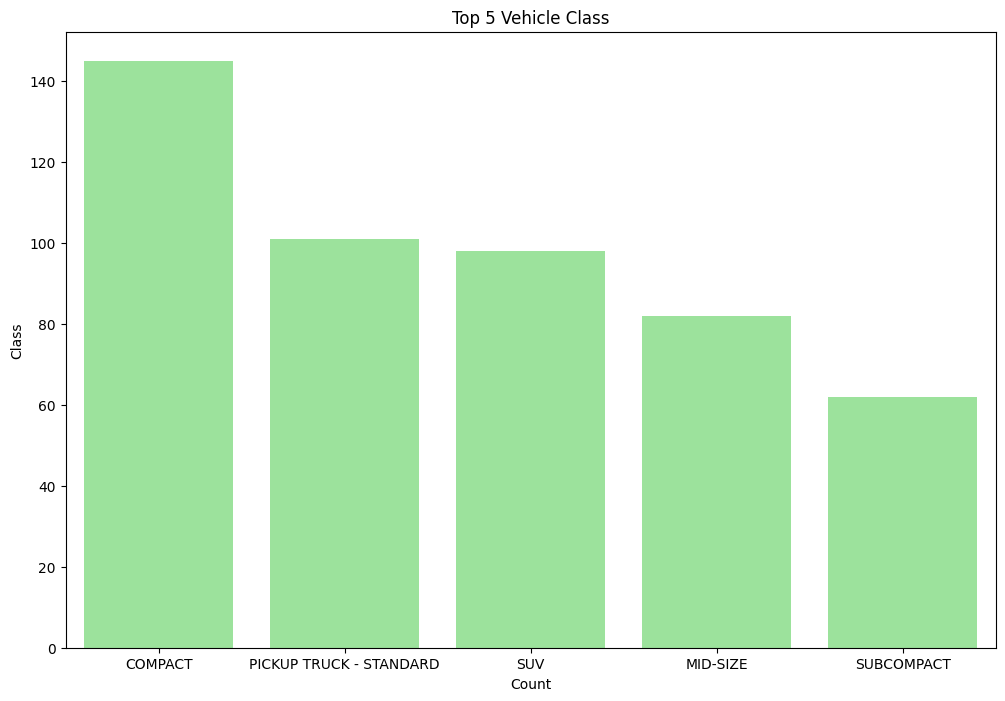

In [11]:
# Vehicle class bar chart
plt.figure(figsize = (12, 8))
sns.countplot(x = 'vehicle_class', 
            data = df,
            order = df['vehicle_class'].value_counts().nlargest(5).index,
            color = 'lightgreen')
plt.title('Top 5 Vehicle Class')
plt.xlabel('Count')
plt.ylabel('Class')
plt.show()

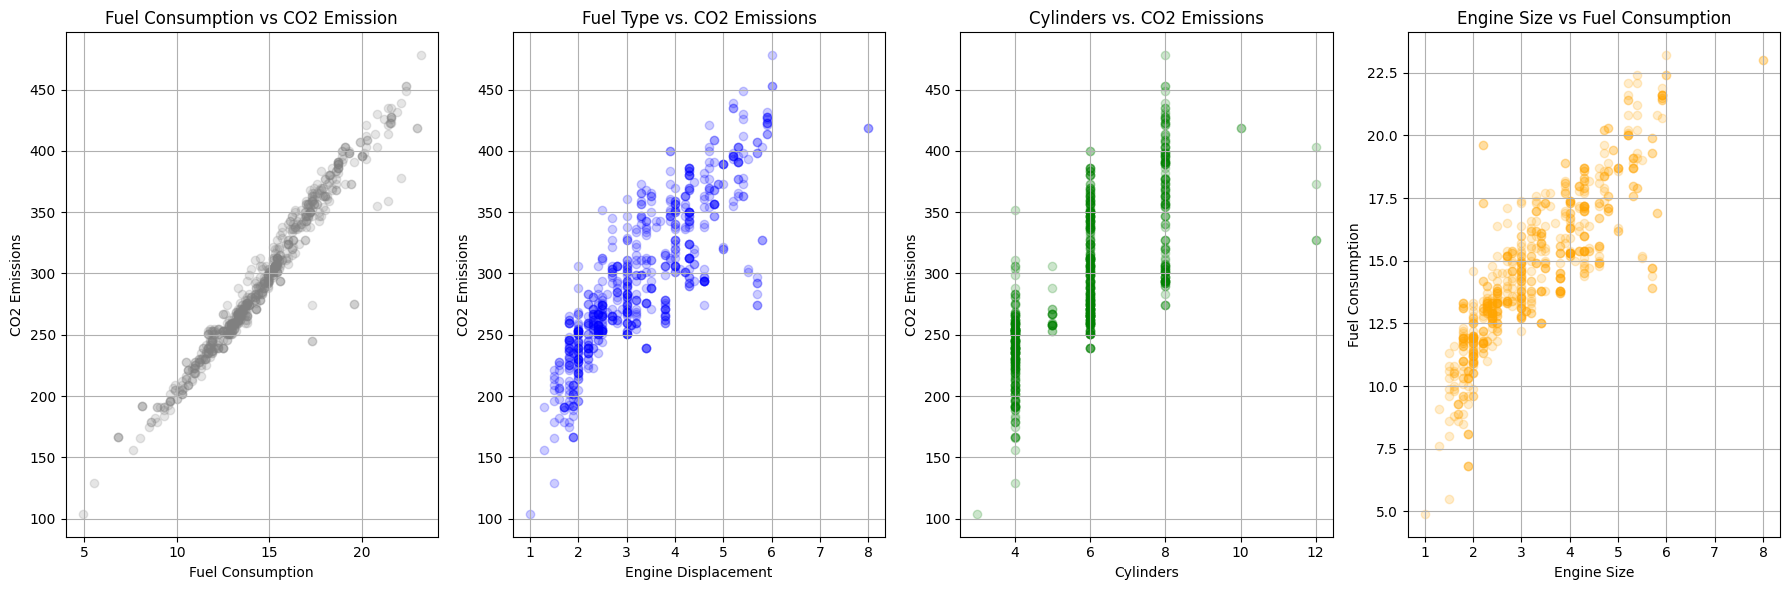

In [12]:
# Feature pairs scatter plot
fig, axes = plt.subplots(1, 4, figsize=(18, 6))

axes[0].scatter(df['fuel_consumption'],df['co2_emissions'], marker= 'o', color = 'gray', alpha = 0.2)
axes[0].set_title('Fuel Consumption vs CO2 Emission')
axes[0].set_xlabel('Fuel Consumption')
axes[0].set_ylabel('CO2 Emissions')
axes[0].grid()

axes[1].scatter(df['engine_size'], df['co2_emissions'], marker='o', color='blue', alpha = 0.2)
axes[1].set_title('Fuel Type vs. CO2 Emissions')
axes[1].set_xlabel('Engine Displacement')
axes[1].set_ylabel('CO2 Emissions')
axes[1].grid()

axes[2].scatter(df['cylinders'], df['co2_emissions'], marker='o', color='green',  alpha = 0.2)
axes[2].set_title('Cylinders vs. CO2 Emissions')
axes[2].set_xlabel('Cylinders')
axes[2].set_ylabel('CO2 Emissions')
axes[2].grid()

axes[3].scatter(df['engine_size'], df['fuel_consumption'], marker='o', color='orange',  alpha = 0.2)
axes[3].set_title('Engine Size vs Fuel Consumption')
axes[3].set_xlabel('Engine Size')
axes[3].set_ylabel('Fuel Consumption')
axes[3].grid()

plt.tight_layout()
plt.show()

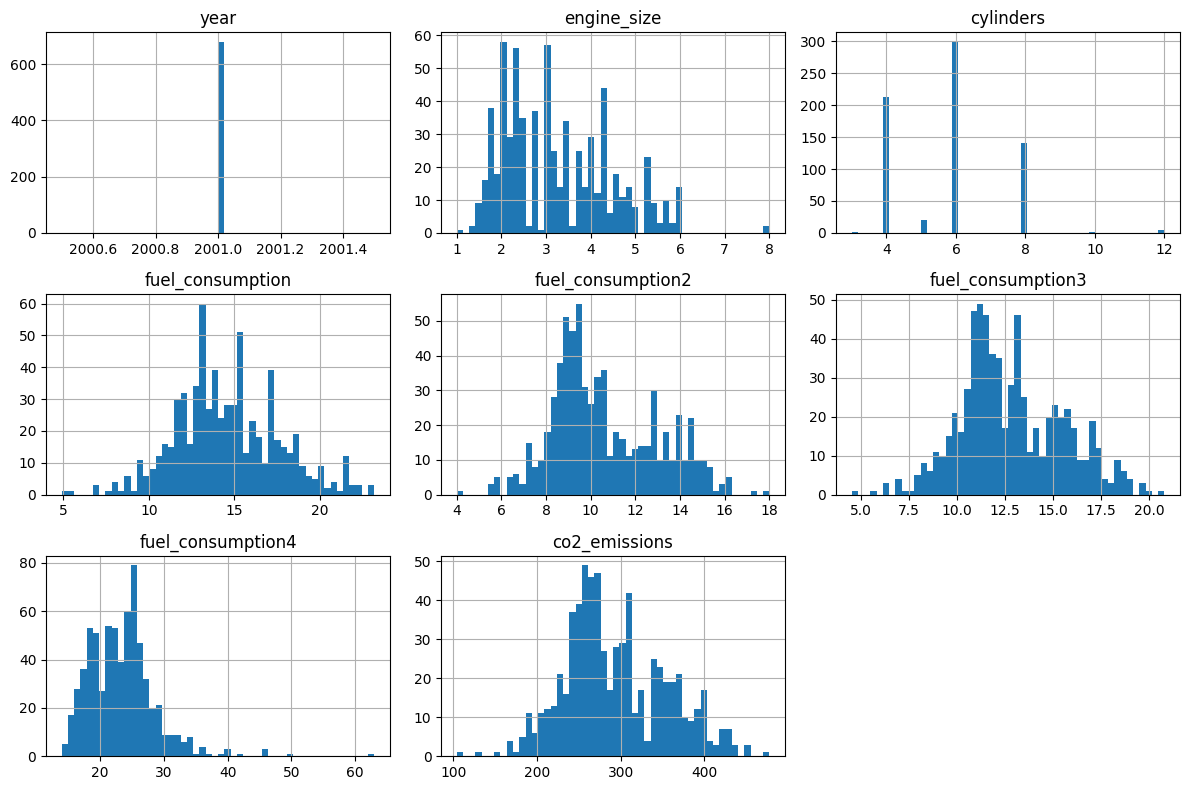

In [13]:
# Features histogram to check distribution
df.hist(bins = 50, figsize = (12, 8))
plt.tight_layout()
plt.show()

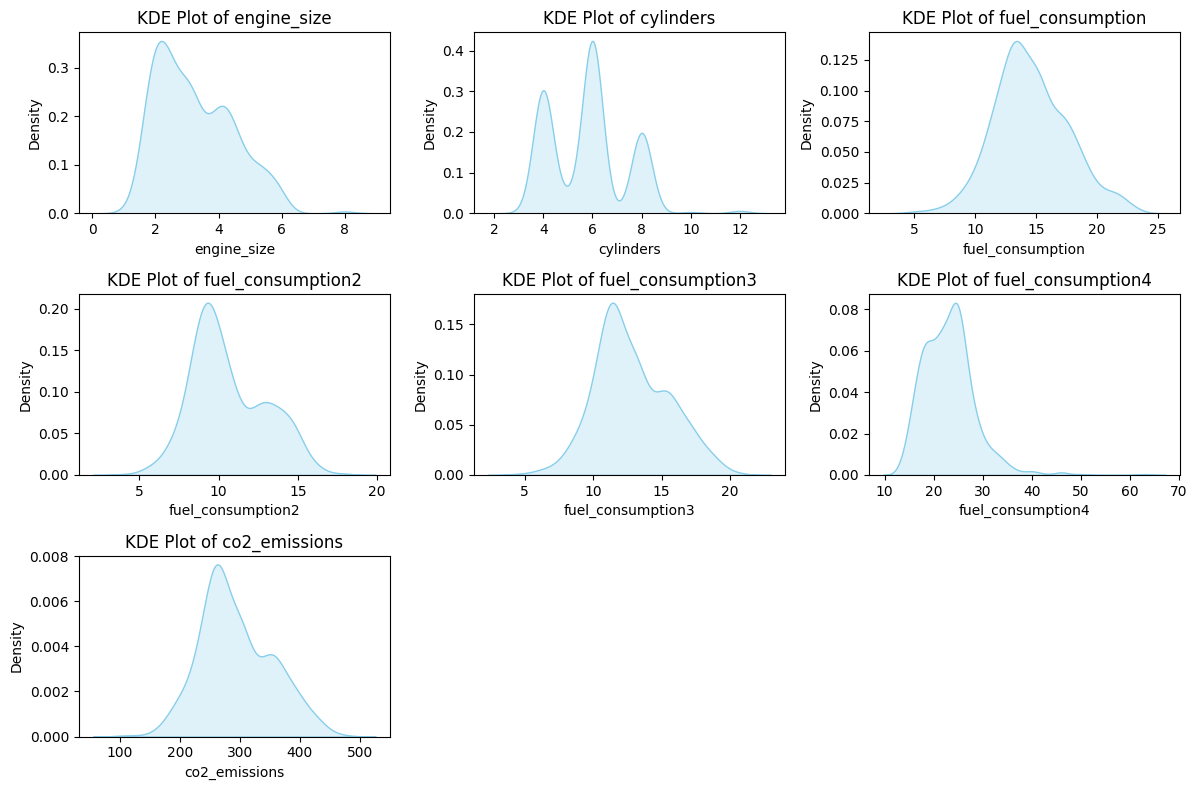

In [14]:
# KDE Plot for each numerical feature to check distribution and skewness
plt.figure(figsize=(12, 8))

# Filter columns with non-zero variance
non_zero_var_columns = df.select_dtypes(exclude='object').columns[df.select_dtypes(exclude='object').nunique() > 1]

for idx, column in enumerate(non_zero_var_columns, 1):
    plt.subplot(3, 3, idx)
    sns.kdeplot(df[column], fill=True, color="skyblue")
    plt.title(f"KDE Plot of {column}")
    plt.xlabel(column)
    plt.ylabel("Density")
plt.tight_layout()
plt.show()

In [15]:
# Feature selection to predictors with high correlation to y variable
num_df = df.select_dtypes(exclude = 'object')
df_corr = num_df.corr()

print('Top 5 Highly Correlated Values with co2_emissions:')
df_corr['co2_emissions'].sort_values(ascending=False).head(6)[1:]

Top 5 Highly Correlated Values with co2_emissions:


fuel_consumption3    0.984805
fuel_consumption     0.974848
fuel_consumption2    0.960852
engine_size          0.850551
cylinders            0.746058
Name: co2_emissions, dtype: float64

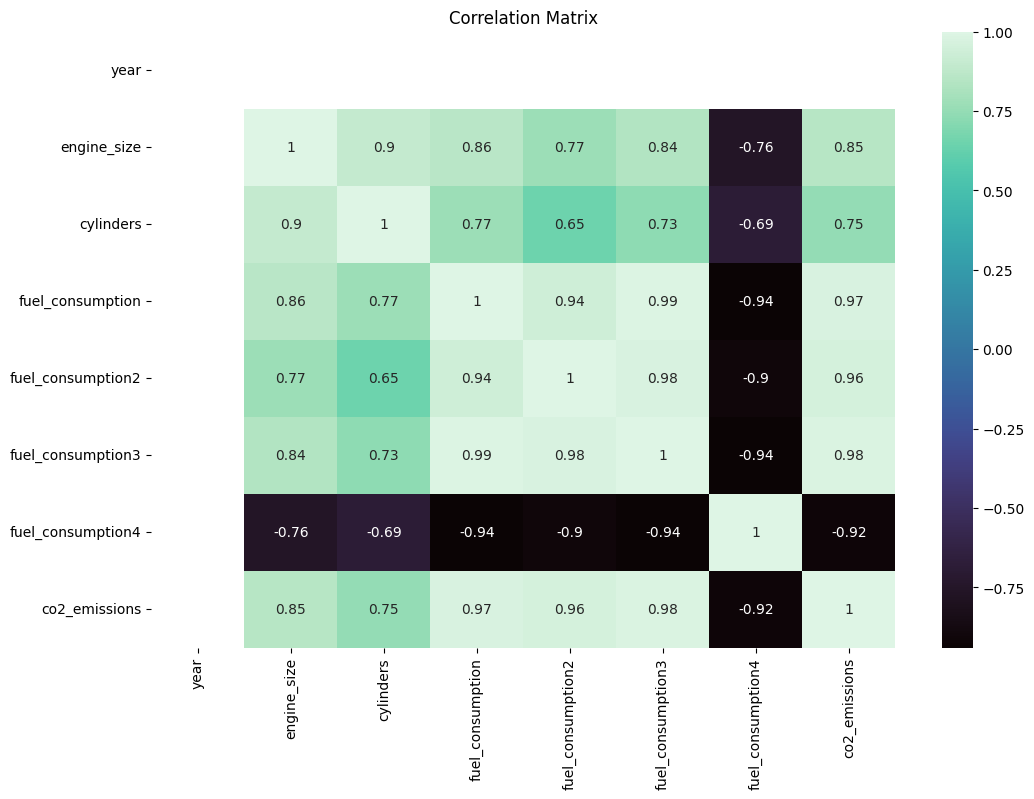

In [16]:
# Correlation matrix 
plt.figure(figsize = (12, 8))
sns.heatmap(df_corr, annot = True, cmap = 'mako')
plt.title('Correlation Matrix')
plt.show()

#### Data Preprocessing

In [17]:
# Drop unnecessary and redundant columns
df.drop(['year', 'fuel_consumption2', 'fuel_consumption3', 'fuel_consumption4'], axis=1, inplace=True)

In [18]:
df.shape

(679, 9)

In [19]:
# Label encoder to transform object data into numeric
categorical_cols = df.select_dtypes('object').columns

# Apply LabelEncoder to each categorical column
for col in categorical_cols:
    df[col] = LabelEncoder().fit_transform(df[col])

In [20]:
df.columns

Index(['maker', 'model', 'vehicle_class', 'engine_size', 'cylinders',
       'transmission', 'fuel', 'fuel_consumption', 'co2_emissions'],
      dtype='object')

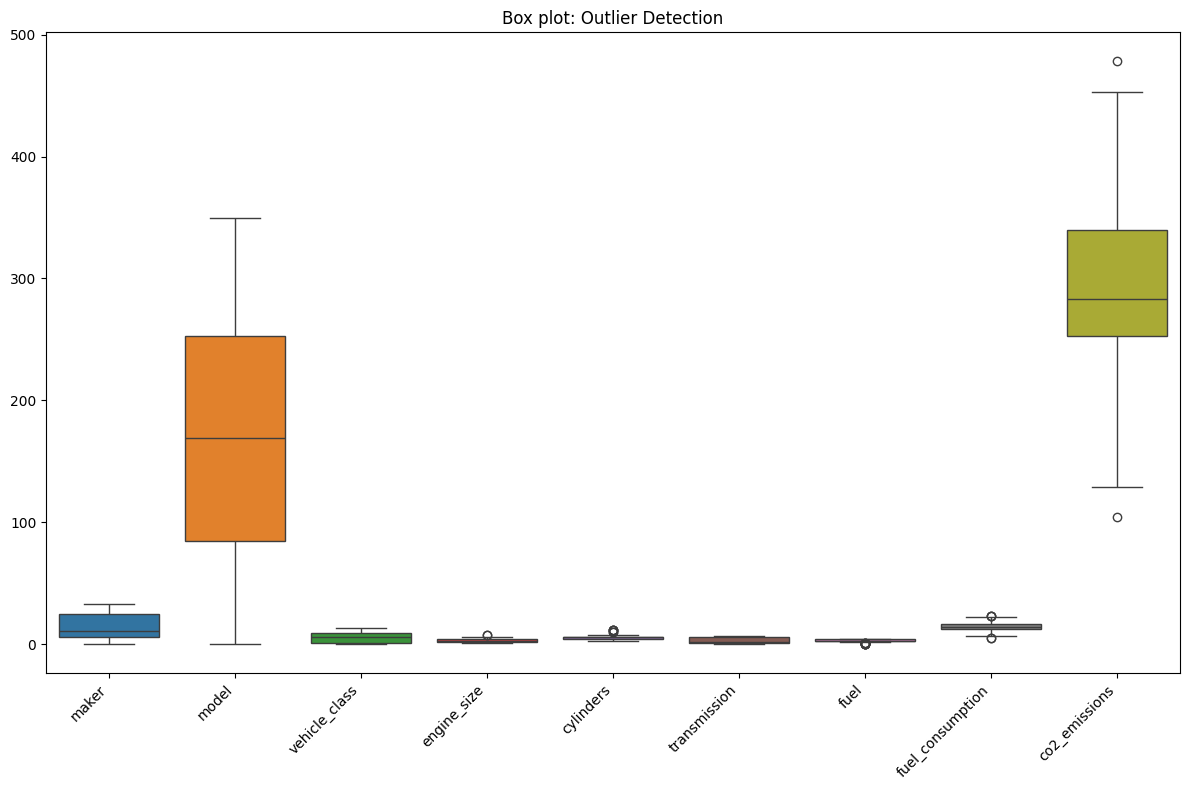

In [21]:
# Box plot to check outlier
plt.figure(figsize=(12, 8))
sns.boxplot(data=df[['maker', 'model', 'vehicle_class', 'engine_size', 'cylinders',
       'transmission', 'fuel', 'fuel_consumption', 'co2_emissions']])

plt.title('Box plot: Outlier Detection')
plt.xticks(rotation=45, ha='right')  
plt.tight_layout()  
plt.show()


In [22]:
# Split data into x (independent), y (dependent) variable
x = df.drop(['co2_emissions'], axis = 1).values
y = df['co2_emissions'].values

In [23]:
# Split data for prediction
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size = 0.2, random_state = 42)

In [24]:
# Robust scaler - less sensitive to skewed / data with outliers, ensures stable features
rc = RobustScaler()
x_train = rc.fit_transform(x_train)
x_test= rc.transform(x_test)

#### Data Modeling, Prediction
##### Model Overview

In [25]:
# Implement ml models (regressors)
regressors = {
    'SVM': SVR(),
    'XGBoost': XGBRegressor()
}

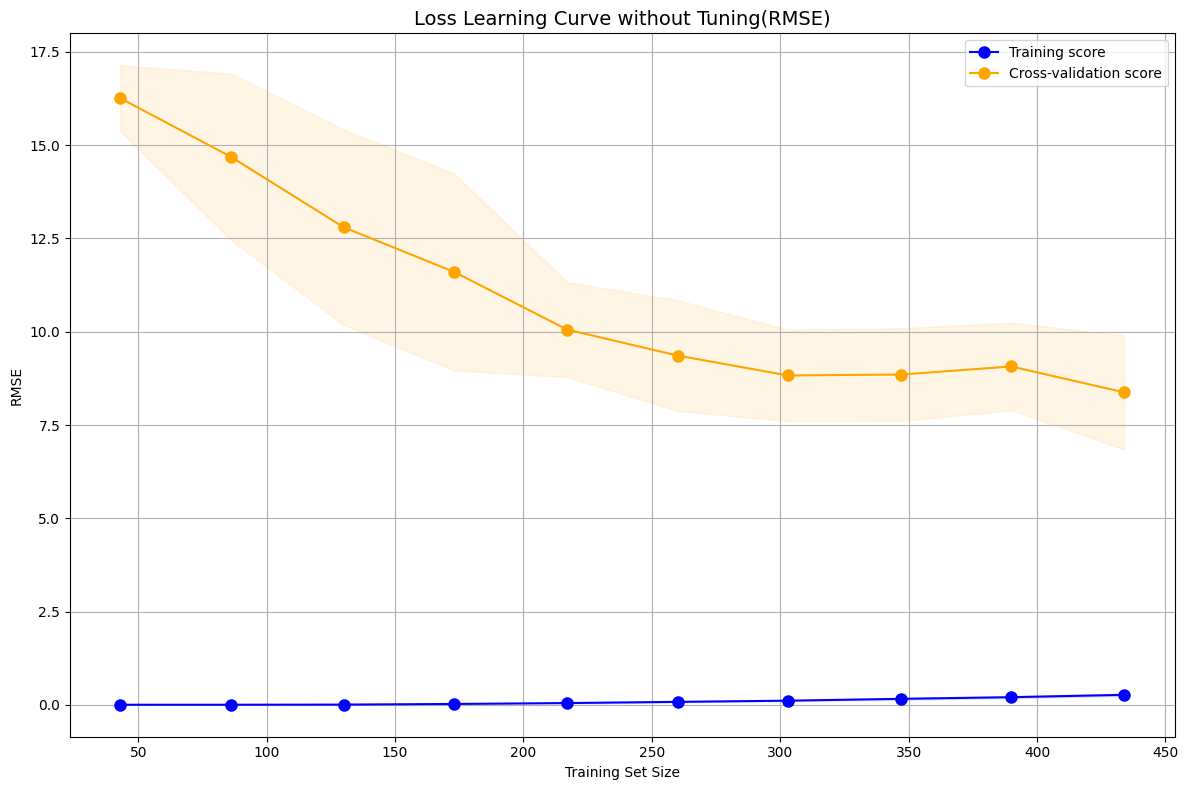

In [26]:
# Learning Curve for XGBoost wihtout parameter tuning 
train_sizes, train_scores, test_scores = learning_curve(
    estimator=XGBRegressor(),
    X=x_train,
    y=y_train,
    train_sizes=np.linspace(0.1, 1.0, 10),
    cv=5,
    scoring='neg_mean_squared_error',  
    n_jobs=-1
)

# Convert negative MSE to RMSE
train_scores_mean = np.sqrt(-train_scores).mean(axis=1)
train_scores_std = np.sqrt(-train_scores).std(axis=1)
test_scores_mean = np.sqrt(-test_scores).mean(axis=1)
test_scores_std = np.sqrt(-test_scores).std(axis=1)

# Plotting the learning curve with RMSE
plt.figure(figsize=(12, 8))
plt.plot(train_sizes, train_scores_mean, label="Training score", color="blue", marker='o', linestyle='-', markersize=8)
plt.fill_between(train_sizes, train_scores_mean - train_scores_std, train_scores_mean + train_scores_std, alpha=0.1, color="blue")
plt.plot(train_sizes, test_scores_mean, label="Cross-validation score", color="orange", marker='o', linestyle='-', markersize=8)
plt.fill_between(train_sizes, test_scores_mean - test_scores_std, test_scores_mean + test_scores_std, alpha=0.1, color="orange")

# Add plot labels and title
plt.title("Loss Learning Curve without Tuning(RMSE)", fontsize=14)
plt.xlabel("Training Set Size")
plt.ylabel("RMSE")
plt.legend(loc="best")
plt.grid(True)
plt.tight_layout()
plt.show()


In [27]:
# Check base model performance using cross_val_score
for key, regressor in regressors.items():
    regressor.fit(x_train, y_train)
    training_score = cross_val_score(regressor, x_train, y_train, cv = 5)
    print(f"{regressor.__class__.__name__} Training Score: {round(training_score.mean() * 100, 2)}%")

SVR Training Score: 65.13%
XGBRegressor Training Score: 97.99%


##### Hyperparameter Tuning

In [28]:
# Tune the best base model to resolve the issue (overfitting)
xg_params = {
    'objective': ['reg:squarederror'],
    'eta': [0.03, 0.04],  
    'alpha': [10, 12],  
    'lambda': [10, 12],  
    'gamma': [10, 12],  
    'max_depth': [1, 2],  
    'min_child_weight': [2, 4], 
    'subsample': [0.04, 0.5],  
    'colsample_bytree': [ 0.6, 0.7],  
    'eval_metric': ['rmse']
}

xg_grid = GridSearchCV(XGBRegressor(), xg_params, cv=5, n_jobs=-1)
xg_grid.fit(x_train, y_train)

# New  model with best parameters
xgb = xg_grid.best_estimator_

print(f'Best parameters for XGB: {xg_grid.best_params_}')

Best parameters for XGB: {'alpha': 10, 'colsample_bytree': 0.7, 'eta': 0.04, 'eval_metric': 'rmse', 'gamma': 10, 'lambda': 10, 'max_depth': 2, 'min_child_weight': 2, 'objective': 'reg:squarederror', 'subsample': 0.5}


In [29]:
# Check tuned model training cv score
xgb__training_score= cross_val_score(xgb, x_train, y_train, cv = 5)
print(f'{xgb.__class__.__name__} Tuned Training Score: {round(xgb__training_score.mean()* 100,2)}%')

XGBRegressor Tuned Training Score: 92.95%


#### Evaluation

In [30]:
# Tuned model metrics
y_pred = xgb.predict(x_test)
r2 = r2_score(y_test, y_pred)
rmse = root_mean_squared_error(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)

print('Tuned XGBoost Metrics ')
print(f'R2 Score: {round(r2* 100, 2)}%')
print(f'RMSE: {round(rmse, 2)}%')
print(f'MAE: {round(mae, 2)}%')

Tuned XGBoost Metrics 
R2 Score: 94.68%
RMSE: 13.49%
MAE: 9.51%


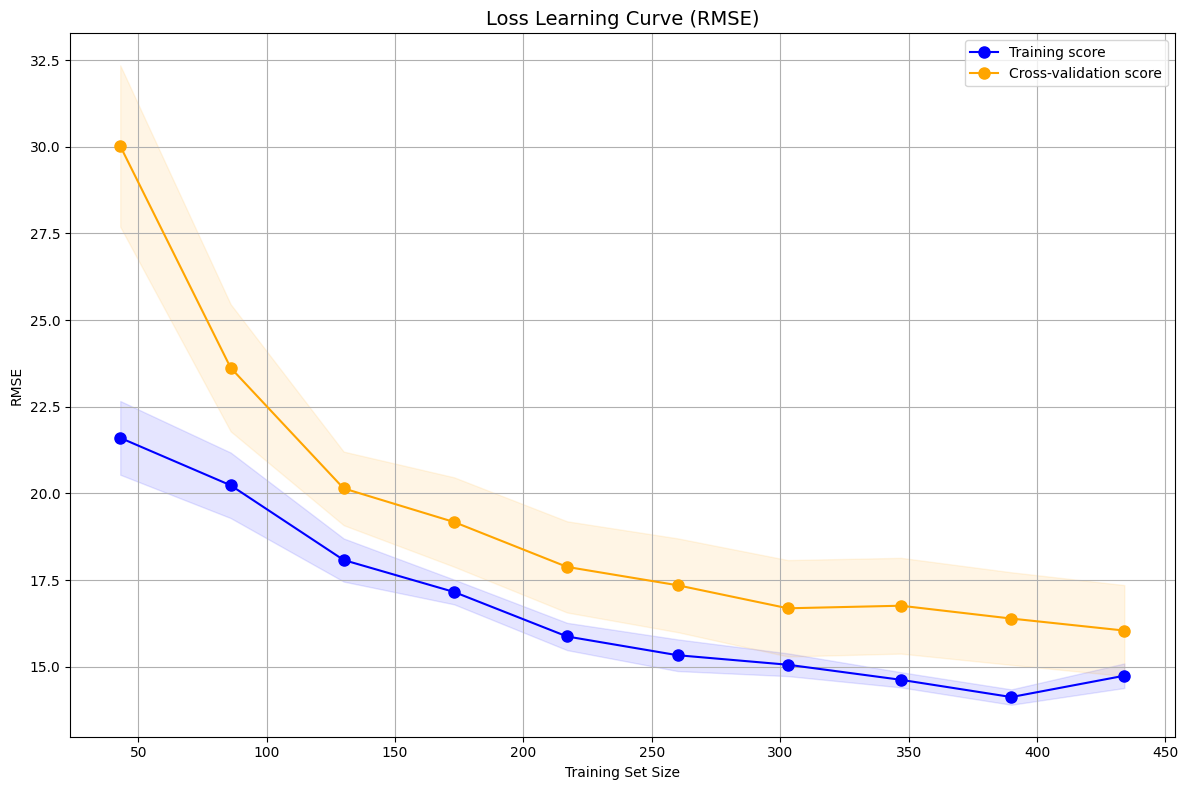

In [31]:
# Learning Curve for XGBoost with RMSE
train_sizes, train_scores, test_scores = learning_curve(
    estimator=xgb,
    X=x_train,
    y=y_train,
    train_sizes=np.linspace(0.1, 1.0, 10),
    cv=5,
    scoring='neg_mean_squared_error',  
    n_jobs=-1
)

# Convert negative MSE to RMSE
train_scores_mean = np.sqrt(-train_scores).mean(axis=1)
train_scores_std = np.sqrt(-train_scores).std(axis=1)
test_scores_mean = np.sqrt(-test_scores).mean(axis=1)
test_scores_std = np.sqrt(-test_scores).std(axis=1)

# Plotting the learning curve with RMSE
plt.figure(figsize=(12, 8))
plt.plot(train_sizes, train_scores_mean, label="Training score", color="blue", marker='o', linestyle='-', markersize=8)
plt.fill_between(train_sizes, train_scores_mean - train_scores_std, train_scores_mean + train_scores_std, alpha=0.1, color="blue")
plt.plot(train_sizes, test_scores_mean, label="Cross-validation score", color="orange", marker='o', linestyle='-', markersize=8)
plt.fill_between(train_sizes, test_scores_mean - test_scores_std, test_scores_mean + test_scores_std, alpha=0.1, color="orange")

# Add plot labels and title
plt.title("Loss Learning Curve (RMSE)", fontsize=14)
plt.xlabel("Training Set Size")
plt.ylabel("RMSE")
plt.legend(loc="best")
plt.grid(True)
plt.tight_layout()
plt.show()


In [32]:
# Extract the last 5 actual CO2 emissions values from y_test
actual_co2_emissions = y_test[-5:]

# Get the last 5 rows of the test set (features) from x_test
last_5_rows = x_test[-5:]

# Predict CO2 emissions for these rows using the base model
predictions_base_model = xgb.predict(last_5_rows)

# Combine actual CO2 emissions and predicted CO2 emissions into a DataFrame
comparison_df = pd.DataFrame({
    'Actual CO2 Emissions': actual_co2_emissions,
    'Predicted CO2 Emissions': predictions_base_model
})

# Display the comparison
print("Side-by-side comparison of actual and predicted CO2 emissions:")
print(comparison_df)


Side-by-side comparison of actual and predicted CO2 emissions:
   Actual CO2 Emissions  Predicted CO2 Emissions
0                   255               252.229324
1                   271               284.503021
2                   290               283.261383
3                   363               363.438629
4                   269               278.882568
